<a href="https://colab.research.google.com/github/pablofierro92/Hydro_-2-1-D_relativistic/blob/main/Copy_FMEO_Hidrodinamica_2plus1D_Colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Initial-state memory with simplified (2+1)D relativistic hydrodynamics


We solve boost-invariant, transverse ideal relativistic hydrodynamics in Milne coordinates $(\tau,x,y,\eta_s)$ with a constant equation of state $p=c_s^2 e$. The transverse grid is two-dimensional, while longitudinal Bjorken expansion appears through source terms. Hot-spot initial conditions are propagated by local conservation equations; the final mean transverse momentum is **not assigned as a direct function of the initial compactness**.

The last stage is a deliberately simplified constant-proper-time thermal emission model. Its purpose is to test the analysis pipeline and the sensitivity of final $p_T$ correlations to fluctuating transverse profiles.

### Conservation equations
Let $E=T^{\tau\tau}$, $M_i=T^{\tau i}$, $p=c_s^2 e$, $\gamma=(1-v_x^2-v_y^2)^{-1/2}$ and $w=e+p$. Then
$$E=w\gamma^2-p,\qquad M_i=w\gamma^2v_i,$$
$$\partial_\tau E+\partial_i M_i=-\frac{E+p}{\tau},$$
$$\partial_\tau M_i+\partial_j(M_iv_j+p\delta_{ij})=-\frac{M_i}{\tau}.$$
Numerically we use a first-order local Lax–Friedrichs/Rusanov finite-volume update, zero-gradient boundaries, a positivity floor, and a conservative Courant step. This is **low resolution and numerically diffusive**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

SEED = 20261020
rng = np.random.default_rng(SEED)
OUT = Path("hydro_memory_outputs")
OUT.mkdir(exist_ok=True)

# Computation: reduce N_EVENTS to 9 for a quick test; increase only after validation.
N_EVENTS = 3000
GRID = 32
BOX_FM = 8.0
DX = BOX_FM / GRID
TAU0, TAUF = 0.35, 1.5  # fm/c; fixed final proper time (toy)
CS2 = 1/3
CFL = 0.28
E_FLOOR = 1e-8
N_SPOTS = (1, 3, 5)
# Mean characteristic hot-spot width (fm)
SPOT_WIDTH_FM = 0.33

# Log-normal width fluctuations
SIGMA_WIDTH = 0.25

# Optional physical/numerical bounds (fm)
WIDTH_MIN_FM = 0.20
WIDTH_MAX_FM = 0.65
CENTER_SIGMA_FM = 0.55
TOTAL_ENERGY = 55.0  # arbitrary model normalization; held fixed
E_TO_T = 0.205   # GeV / (arb. energy-density)^(1/4) thermal emission proxy
TARGET_MULT = 85
PT_CUT = (0.15, 1.5)  # GeV

x = (np.arange(GRID)+0.5)*DX-BOX_FM/2
X,Y = np.meshgrid(x,x,indexing="ij")
print('Grid:', GRID, 'x', GRID, '| events:', N_EVENTS, '| tau:', TAU0, '->', TAUF)


Grid: 32 x 32 | events: 3000 | tau: 0.35 -> 1.5


## 1 — Generate transverse energy-density profiles

Each event has a fixed integrated initial energy (to reduce trivial total-energy differences). We vary the number and locations of hot spots and the fluctuating weights. The energy-density normalization and transverse length scales are **not tuned to a collision energy**. Later we measure initial compactness and an effective initial-density proxy.

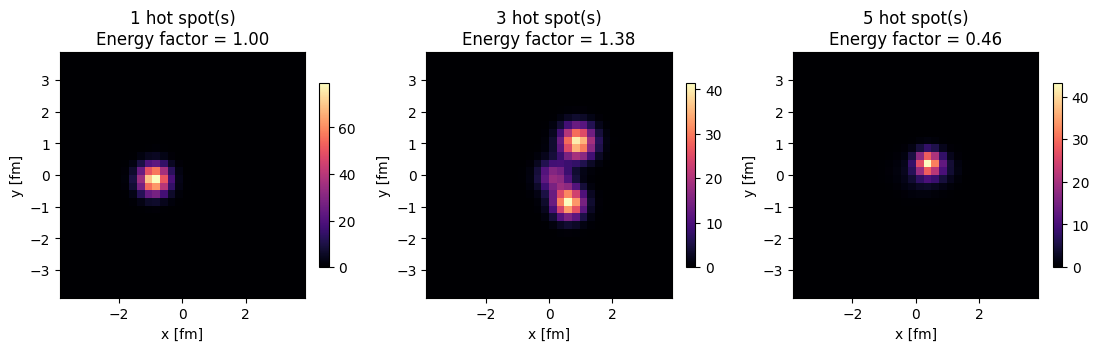

In [ ]:
def make_initial(nspots, rg):

    # --------------------------------------------------
    # Random hot-spot centers
    # --------------------------------------------------
    centers = rg.normal(
        0,
        CENTER_SIGMA_FM,
        size=(nspots, 2)
    )

    # --------------------------------------------------
    # Random hot-spot weights
    # --------------------------------------------------
    weights = rg.lognormal(
        mean=0.0,
        sigma=0.5,
        size=nspots
    )

    # --------------------------------------------------
    # Independent fluctuating width for each hot spot
    # --------------------------------------------------
    widths = SPOT_WIDTH_FM * rg.lognormal(
        mean=0.0,
        sigma=SIGMA_WIDTH,
        size=nspots
    )

    widths = np.clip(
        widths,
        WIDTH_MIN_FM,
        WIDTH_MAX_FM
    )

    # --------------------------------------------------
    # Construct transverse energy density
    # --------------------------------------------------
    density = np.zeros_like(X, dtype=float)

    for (cx, cy), wi, sigma_i in zip(
        centers,
        weights,
        widths
    ):

        density += (
            wi / (2.0 * np.pi * sigma_i**2)
            * np.exp(
                -(
                    (X - cx)**2
                    + (Y - cy)**2
                ) / (2.0 * sigma_i**2)
            )
        )

    # --------------------------------------------------
    # Event-by-event fluctuation of total initial energy
    # --------------------------------------------------
    SIGMA_ENERGY = 0.40

    energy_factor = rg.lognormal(
        mean=-0.5 * SIGMA_ENERGY**2,
        sigma=SIGMA_ENERGY
    )

    event_energy = TOTAL_ENERGY * energy_factor

    # Normalize density to the fluctuating event energy
    integral = density.sum() * DX**2

    if integral <= 0:
        raise ValueError("Initial density has zero or negative integral.")

    density *= event_energy / integral

    # --------------------------------------------------
    # Energy-weighted center
    # --------------------------------------------------
    norm = density.sum()

    if norm <= 0:
        raise ValueError("Initial density normalization is zero.")

    xc = (density * X).sum() / norm
    yc = (density * Y).sum() / norm

    # --------------------------------------------------
    # Initial transverse radius
    # --------------------------------------------------
    rad2 = (
        density
        * (
            (X - xc)**2
            + (Y - yc)**2
        )
    ).sum() / norm

    r_init = np.sqrt(rad2)

    compactness = 1.0 / np.sqrt(
        max(rad2, 1e-12)
    )

    # --------------------------------------------------
    # Initial density inhomogeneity proxy
    # --------------------------------------------------
    #
    # IMPORTANT:
    # Since the total energy now fluctuates event-by-event,
    # normalize q_proxy with event_energy, not TOTAL_ENERGY.
    #
    q_proxy = (
        (density**2).sum() * DX**2
        / event_energy**2
    )

    return density, {
        "r_init": float(r_init),
        "compactness": float(compactness),
        "q_proxy": float(q_proxy),

        # Hot-spot width information
        "width_mean": float(np.mean(widths)),
        "width_std": float(np.std(widths)),

        # NEW: event-by-event energy information
        "energy_factor": float(energy_factor),
        "initial_energy": float(event_energy)
    }


# ============================================================
# Example initial profiles
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(11, 3.4),
    constrained_layout=True
)

for ax, nh in zip(axes, N_SPOTS):

    dens, obs = make_initial(
        nh,
        np.random.default_rng(SEED + nh)
    )

    im = ax.imshow(
        dens.T,
        origin='lower',
        extent=[
            x[0],
            x[-1],
            x[0],
            x[-1]
        ],
        cmap='magma'
    )

    ax.set_title(
        f'{nh} hot spot(s)\n'
        f'Energy factor = {obs["energy_factor"]:.2f}'
    )

    ax.set_xlabel('x [fm]')
    ax.set_ylabel('y [fm]')

    fig.colorbar(
        im,
        ax=ax,
        shrink=0.75
    )

plt.savefig(
    OUT / 'initial_profiles.png',
    dpi=150
)

plt.show()

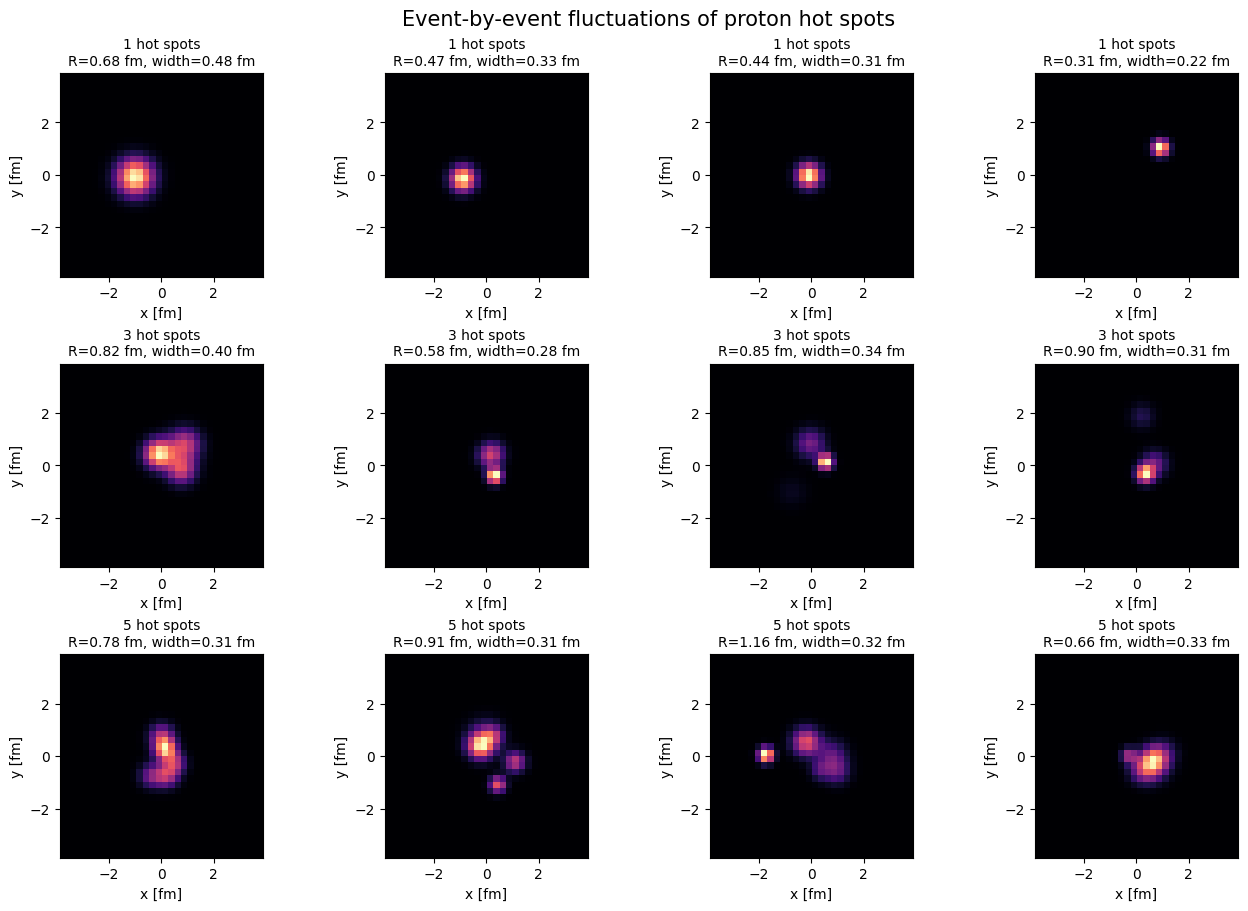

In [ ]:
# Visualize event-by-event hot-spot width fluctuations

fig, axes = plt.subplots(
    3, 4, figsize=(13, 9),
    constrained_layout=True
)

for row, nh in enumerate([1, 3, 5]):

    for col in range(4):

        rg = np.random.default_rng(
            20261020 + row * 100 + col
        )

        density, obs = make_initial(nh, rg)

        ax = axes[row, col]

        im = ax.imshow(
            density.T,
            origin="lower",
            extent=[
                x[0], x[-1],
                x[0], x[-1]
            ],
            cmap="magma"
        )

        ax.set_title(
            f"{nh} hot spots\n"
            f"R={obs['r_init']:.2f} fm, "
            f"width={obs['width_mean']:.2f} fm",
            fontsize=10
        )

        ax.set_xlabel("x [fm]")
        ax.set_ylabel("y [fm]")

plt.suptitle(
    "Event-by-event fluctuations of proton hot spots",
    fontsize=15
)

plt.savefig(
    OUT / "fluctuating_hotspot_widths.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 2 — Conservative hydro solver

Primitive-variable inversion is iterated from the conserved quantities. The Rusanov numerical flux uses an upper bound of the characteristic speed, $a=1$, so the scheme prioritizes robustness over accuracy. A longitudinal source step approximates Bjorken dilution. Any numerical positivity repairs are counted as diagnostics.

Steps: 24 | E integral tau0: 55.0 | final E integral: 8.149 (Bjorken expansion should decrease it)
Max fluid speed: 0.929


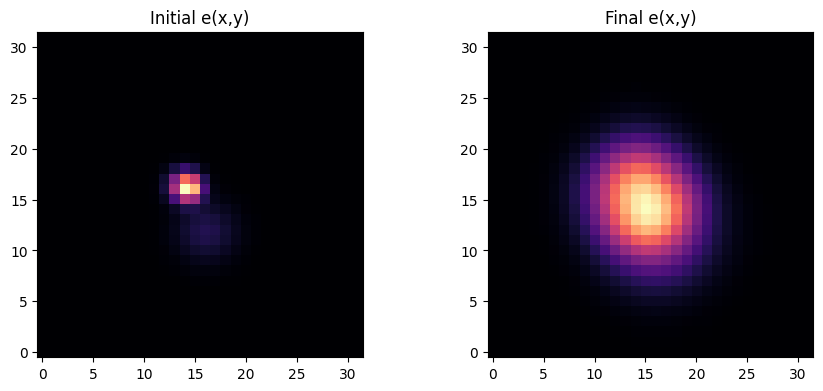

In [ ]:
def primitive(U):
    E=np.maximum(U[0],E_FLOOR)
    Mx,My=U[1],U[2]
    # Repair any locally unphysical momentum before inversion.
    m=np.hypot(Mx,My)
    cap=np.maximum(E*(1-1e-8), E_FLOOR)
    scale=np.minimum(1.0,cap/np.maximum(m,1e-30))
    Mx,My=Mx*scale,My*scale
    p=CS2*E.copy()
    for _ in range(30):
        vdotM=(Mx*Mx+My*My)/np.maximum(E+p,E_FLOOR)
        newp=CS2*np.maximum(E-vdotM,E_FLOOR)
        if np.max(np.abs(newp-p)) < 1e-10: break
        p=0.5*(p+newp)
    vx=Mx/np.maximum(E+p,E_FLOOR)
    vy=My/np.maximum(E+p,E_FLOOR)
    vsq=np.minimum(vx*vx+vy*vy, 1-1e-9)
    e=np.maximum(E-(Mx*vx+My*vy),E_FLOOR)
    return e,p,vx,vy

def flux(U,axis):
    e,p,vx,vy=primitive(U)
    if axis==0:
        return np.stack([U[1], U[1]*vx+p, U[2]*vx])
    return np.stack([U[2], U[1]*vy, U[2]*vy+p])

def divergence_flux(U,axis):
    # Rusanov interface flux: max wave speed conservatively bounded by 1.
    sp_axis=axis+1
    up=np.pad(U,((0,0),(1,1) if axis==0 else (0,0),(1,1) if axis==1 else (0,0)),mode='edge')
    left=np.take(up,np.arange(0,GRID+1),axis=sp_axis)
    right=np.take(up,np.arange(1,GRID+2),axis=sp_axis)
    face=0.5*(flux(left,axis)+flux(right,axis)) - 0.5*(right-left)
    return np.diff(face,axis=sp_axis)/DX

def repair(U):
    U[0]=np.maximum(U[0],E_FLOOR)
    mag=np.hypot(U[1],U[2]); cap=0.999999*U[0]
    fac=np.minimum(1,cap/np.maximum(mag,1e-30))
    U[1]*=fac;U[2]*=fac
    return U

def rhs(U,tau):
    e,p,vx,vy=primitive(U)
    src=np.stack([-(U[0]+p)/tau,-U[1]/tau,-U[2]/tau])
    return -divergence_flux(U,0)-divergence_flux(U,1)+src

def evolve(initial, save_history=False):
    U=np.stack([initial.copy(),np.zeros_like(initial),np.zeros_like(initial)])
    tau=TAU0
    dt=CFL*DX/np.sqrt(2)  # conservative 2-D CFL restriction
    history=[]
    if save_history: history.append((tau,U.copy()))
    nsteps=0
    while tau < TAUF-1e-10:
        h=min(dt,TAUF-tau)
        # SSP RK2 / Heun update; source evaluated at each stage
        A=repair(U+h*rhs(U,tau))
        U=repair(0.5*(U+A+h*rhs(A,tau+h)))
        tau+=h;nsteps+=1
        if save_history and (nsteps%12==0 or tau>=TAUF-1e-10):
            history.append((tau,U.copy()))
    e,p,vx,vy=primitive(U)
    return {'e':e,'vx':vx,'vy':vy,'history':history,'nsteps':nsteps,
            'integrated_E':float(U[0].sum()*DX**2)}

demo_init,_=make_initial(3,np.random.default_rng(SEED+12))
demo=evolve(demo_init,save_history=True)
print('Steps:',demo['nsteps'],'| E integral tau0:',TOTAL_ENERGY,
      '| final E integral:',round(demo['integrated_E'],3),
      '(Bjorken expansion should decrease it)')
print('Max fluid speed:', round(float(np.hypot(demo['vx'],demo['vy']).max()),4))
fig,axs=plt.subplots(1,2,figsize=(9,3.8),constrained_layout=True)
axs[0].imshow(demo_init.T,origin='lower',cmap='magma');axs[0].set_title('Initial e(x,y)')
axs[1].imshow(demo['e'].T,origin='lower',cmap='magma');axs[1].set_title('Final e(x,y)')
plt.savefig(OUT/'hydro_example.png',dpi=160);plt.show()


## 3 — Thermal emission proxy at fixed proper time

We sample cells with weights proportional to $e^{3/4}\,\Delta x\Delta y$ (an ideal conformal entropy proxy). In the local rest frame we draw massless transverse momenta with $p_T$ distributed as Gamma(shape=2, scale=$T$), with $T\propto e^{1/4}$. We then perform a **two-dimensional transverse Lorentz boost** using the local $v_x,v_y$.

This does **not** implement a proper particle-species-dependent 3+1D Cooper–Frye prescription, longitudinal momentum, resonance decays, hadronic afterburner, or an isothermal freeze-out surface. The output is a diagnostic toy final state.

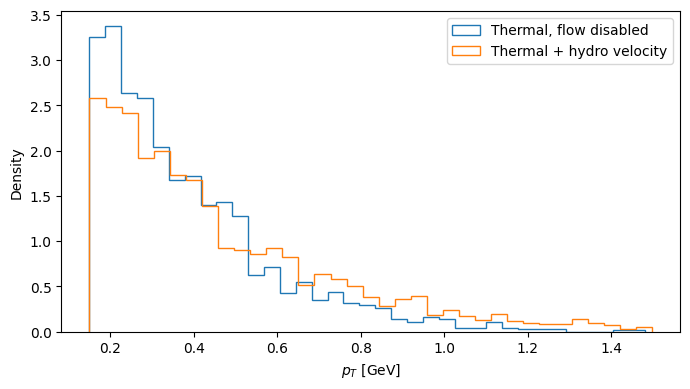

In [ ]:
def emit_particles(fields, n, rg, with_flow=True):
    ee=fields['e']; vx=fields['vx'];vy=fields['vy']
    entropy=np.maximum(ee,0)**0.75
    probs=(entropy/entropy.sum()).ravel()
    idx=rg.choice(probs.size,size=n,p=probs)
    ei=ee.ravel()[idx]
    T=E_TO_T*np.maximum(ei,E_FLOOR)**0.25
    plocal=rg.gamma(shape=2.0,scale=T)
    angle=rg.uniform(-np.pi,np.pi,size=n)
    px=plocal*np.cos(angle); py=plocal*np.sin(angle)
    if with_flow:
        ux=vx.ravel()[idx];uy=vy.ravel()[idx]
        v2=np.minimum(ux*ux+uy*uy,1-1e-9)
        gamma=1/np.sqrt(1-v2)
        dot=ux*px+uy*py
        extra=np.where(v2>1e-12,(gamma-1)*dot/np.maximum(v2,1e-12),0)+gamma*plocal
        px=px+extra*ux;py=py+extra*uy
    pt=np.hypot(px,py)
    lo,hi=PT_CUT
    return pt[(pt>lo)&(pt<hi)]

def characterize_final(fields):
    e=fields['e']; entropy=e**0.75
    vx,vy=fields['vx'],fields['vy']
    return dict(flow_rms=float(np.sqrt(np.sum(entropy*(vx*vx+vy*vy))/entropy.sum())),
                entropy_proxy=float(entropy.sum()*DX**2))

rg=np.random.default_rng(SEED+42)
example_flow=emit_particles(demo,2500,rg,with_flow=True)
example_noflow=emit_particles(demo,2500,rg,with_flow=False)
plt.figure(figsize=(7,4))
plt.hist(example_noflow,bins=35,histtype='step',density=True,label='Thermal, flow disabled')
plt.hist(example_flow,bins=35,histtype='step',density=True,label='Thermal + hydro velocity')
plt.xlabel(r'$p_T$ [GeV]');plt.ylabel('Density');plt.legend();plt.tight_layout()
plt.savefig(OUT/'emission_example.png',dpi=150);plt.show()


In [ ]:
# ============================================================
# NEW CELL — FINAL ENTROPY TO CHARGED MULTIPLICITY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Target mean accepted multiplicity
TARGET_MULT = 85

# Fraction of sampled particles passing pT cuts.
# This factor is only a starting approximation.
ACCEPTANCE_ESTIMATE = 0.72

# Reference event for entropy normalization
reference_rng = np.random.default_rng(SEED + 800)

reference_initial, _ = make_initial(
    3, reference_rng
)

reference_final = evolve(reference_initial)

def final_entropy(fields):
    """
    Entropy proxy per unit space-time rapidity
    at fixed proper time TAUF.

    For a conformal EOS:
        s ~ e^(3/4)

    This is not an absolute physical entropy
    because the proportionality constant is omitted.
    """

    e = np.maximum(fields["e"], E_FLOOR)

    entropy_density = e**0.75

    S = (
        TAUF *
        entropy_density.sum() *
        DX**2
    )

    return float(S)


S_REFERENCE = final_entropy(reference_final)

# Normalization for accepted multiplicity
ALPHA_MULT = (
    TARGET_MULT /
    (ACCEPTANCE_ESTIMATE * S_REFERENCE)
)

print("Reference final entropy =", S_REFERENCE)
print("Entropy-to-multiplicity coefficient =", ALPHA_MULT)


def multiplicity_from_entropy(fields, rg):
    """
    Draw particle multiplicity from final entropy.
    """

    S = final_entropy(fields)

    mean_n = ALPHA_MULT * S

    n = rg.poisson(mean_n)

    return max(12, int(n)), S

Reference final entropy = 8.280720376253555
Entropy-to-multiplicity coefficient = 14.256676978744622


## 4 — Event-by-event ensemble

For each event we reuse the *same initial profile* for a hydrodynamic and a zero-transverse-flow emission control, and use independent particle draws at freeze-out. This **is not** a physical "without hydro" evolution: the latter is an emission ablation on the same evolved energy-density field. We explicitly report this distinction.

Initial total energy is matched across hot-spot classes. The emitted multiplicity is sampled from a Poisson distribution with a common mean; it is not predicted by hadron chemistry or detector response. That choice permits exact-$N_{ch}$ comparisons without selecting disjoint multiplicity populations.

In [ ]:
test_rg = np.random.default_rng(SEED)
test_initial, _ = make_initial(N_SPOTS[0], test_rg)
test_fin = evolve(test_initial)

print(type(test_fin))
print(test_fin.keys())

<class 'dict'>
dict_keys(['e', 'vx', 'vy', 'history', 'nsteps', 'integrated_E'])


In [ ]:
records = []
particle_store = {
    'hydro': [],
    'no_flow': []
}

for event_id in range(N_EVENTS):

    nh = N_SPOTS[event_id % len(N_SPOTS)]

    rg = np.random.default_rng(
        SEED + 10000 + event_id
    )

    # Initial condition
    initial, initial_obs = make_initial(
        nh,
        rg
    )

    # Evolution
    fin = evolve(initial)

    # Final-state observables
    final_obs = characterize_final(fin)

    # Final integrated energy / entropy-like proxy
    final_entropy_proxy = float(
        fin['integrated_E']
    )

    # Particle multiplicity
    # Multiplicity mean correlated with final integrated energy

    energy_ref = TOTAL_ENERGY

    mult_mean = TARGET_MULT * (
    fin['integrated_E'] / energy_ref
    )

# Optional additional event-by-event multiplicity fluctuations
    SIGMA_MULT = 0.15

    mult_factor = rg.lognormal(
    mean=-0.5 * SIGMA_MULT**2,
    sigma=SIGMA_MULT
    )

    mult_mean *= mult_factor

    requested_n = max(
    12,
    int(rg.poisson(mult_mean))
    )

    # Particle emission
    pts_hydro = emit_particles(
        fin,
        requested_n,
        rg,
        with_flow=True
    )

    pts_noflow = emit_particles(
        fin,
        requested_n,
        rg,
        with_flow=False
    )

    particle_store['hydro'].append(
        pts_hydro
    )

    particle_store['no_flow'].append(
        pts_noflow
    )

    records.append({
        'event_id': event_id,
        'n_hotspots': nh,

        'requested_n': requested_n,

        'nch': len(pts_hydro),
        'nch_no_flow': len(pts_noflow),

        'mean_pt_hydro':
            float(pts_hydro.mean())
            if len(pts_hydro) > 1
            else np.nan,

        'mean_pt_no_flow':
            float(pts_noflow.mean())
            if len(pts_noflow) > 1
            else np.nan,

        'final_entropy_proxy':
            final_entropy_proxy,

        **initial_obs,
        **final_obs
    })

    if (event_id + 1) % 6 == 0:
        print(
            'Completed',
            event_id + 1,
            '/',
            N_EVENTS
        )


df = pd.DataFrame(records)

display(
    df.groupby('n_hotspots')[
        [
            'r_init',
            'compactness',
            'q_proxy',
            'flow_rms',
            'initial_energy',
            'final_entropy_proxy',
            'nch',
            'mean_pt_hydro'
        ]
    ].agg(
        ['mean', 'std']
    ).round(3)
)

df.to_csv(
    OUT / 'hydro_event_table.csv',
    index=False
)

print(
    "Saved:",
    OUT / 'hydro_event_table.csv'
)

Completed 6 / 3000
Completed 12 / 3000
Completed 18 / 3000
Completed 24 / 3000
Completed 30 / 3000
Completed 36 / 3000
Completed 42 / 3000
Completed 48 / 3000
Completed 54 / 3000
Completed 60 / 3000
Completed 66 / 3000
Completed 72 / 3000
Completed 78 / 3000
Completed 84 / 3000
Completed 90 / 3000
Completed 96 / 3000
Completed 102 / 3000
Completed 108 / 3000
Completed 114 / 3000
Completed 120 / 3000
Completed 126 / 3000
Completed 132 / 3000
Completed 138 / 3000
Completed 144 / 3000
Completed 150 / 3000
Completed 156 / 3000
Completed 162 / 3000
Completed 168 / 3000
Completed 174 / 3000
Completed 180 / 3000
Completed 186 / 3000
Completed 192 / 3000
Completed 198 / 3000
Completed 204 / 3000
Completed 210 / 3000
Completed 216 / 3000
Completed 222 / 3000
Completed 228 / 3000
Completed 234 / 3000
Completed 240 / 3000
Completed 246 / 3000
Completed 252 / 3000
Completed 258 / 3000
Completed 264 / 3000
Completed 270 / 3000
Completed 276 / 3000
Completed 282 / 3000
Completed 288 / 3000
Completed

r_init        compactness        q_proxy        flow_rms         \
             mean    std        mean    std    mean    std     mean    std   
n_hotspots                                                                   
1           0.481  0.121       2.209  0.552   0.825  0.418    0.609  0.027   
3           0.771  0.185       1.371  0.323   0.435  0.159    0.559  0.029   
5           0.835  0.146       1.235  0.218   0.337  0.100    0.541  0.026   

           initial_energy         final_entropy_proxy            nch         \
                     mean     std                mean    std    mean    std   
n_hotspots                                                                    
1                  54.876  21.940               8.531  3.414  10.923  4.349   
3                  55.226  23.350               8.458  3.579  10.824  4.436   
5                  54.070  22.618               8.231  3.442  10.847  4.540   

           mean_pt_hydro         
                    mean    std  
n_hotspots                       
1                  0.471  0.091  
3                  0.451  0.090  
5                  0.450  0.087

Saved: hydro_memory_outputs/hydro_event_table.csv


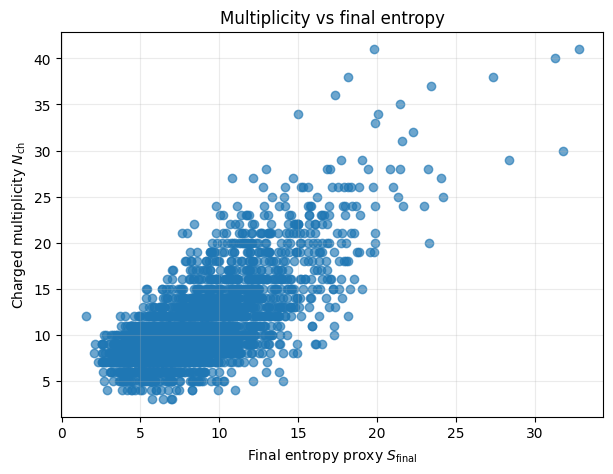

Pearson correlation Nch vs final entropy proxy = 0.7240


In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(
    df['final_entropy_proxy'],
    df['nch'],
    alpha=0.65
)

plt.xlabel(r'Final entropy proxy $S_{\rm final}$')
plt.ylabel(r'Charged multiplicity $N_{\rm ch}$')
plt.title(r'Multiplicity vs final entropy')

plt.grid(alpha=0.25)
plt.show()


# Correlation coefficient
valid = df[['final_entropy_proxy', 'nch']].dropna()

corr = valid['final_entropy_proxy'].corr(valid['nch'])

print(
    f"Pearson correlation Nch vs final entropy proxy = {corr:.4f}"
)

## 5 — Memory at fixed multiplicity, and a permutation control

A weighted residual correlation removes exact multiplicity-bin means. If there are too few repeat events at exactly the same integer multiplicity, we use **5-particle-wide bins**, record the resulting sample size, and refrain from interpreting the result as an exact conditional dependence. Increase `N_EVENTS` to hundreds or thousands for meaningful resolution; this demo is small.


,feature,outcome,rho,n
0,compactness,mean_pt_hydro,0.143,3000
1,compactness,mean_pt_no_flow,0.071,3000
2,q_proxy,mean_pt_hydro,0.115,3000
3,q_proxy,mean_pt_no_flow,0.059,3000
4,r_init,mean_pt_hydro,-0.158,3000
5,r_init,mean_pt_no_flow,-0.070,3000


Observed residual rho=0.143, permutation p=0.0020, N=3000


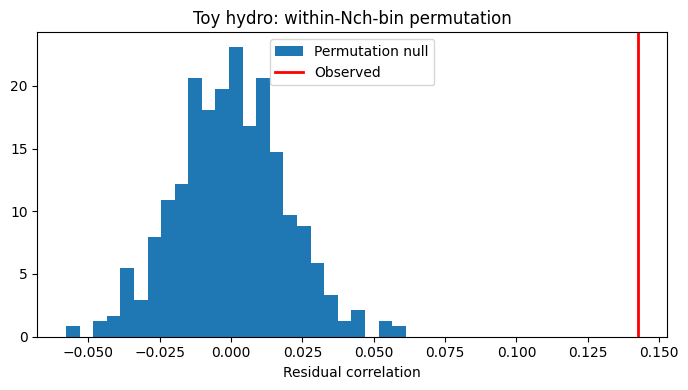

In [ ]:
def residual_correlation(data,xcol,ycol,bin_width=5):
    g=data[[xcol,ycol,'nch']].dropna().copy()
    if len(g)<10:return np.nan, len(g)
    g['mbin']=(g['nch']//bin_width)*bin_width
    # Keep only groups containing at least 3 events
    ct=g.groupby('mbin')['mbin'].transform('size')
    g=g[ct>=3].copy()
    if len(g)<10:return np.nan,len(g)
    xx=g[xcol]-g.groupby('mbin')[xcol].transform('mean')
    yy=g[ycol]-g.groupby('mbin')[ycol].transform('mean')
    if xx.std()==0 or yy.std()==0:return np.nan,len(g)
    return float(np.corrcoef(xx,yy)[0,1]),len(g)

rows=[]
for feature in ['compactness','q_proxy','r_init']:
    for outcome in ['mean_pt_hydro','mean_pt_no_flow']:
        rho,n=residual_correlation(df,feature,outcome)
        rows.append({'feature':feature,'outcome':outcome,'rho':rho,'n':n})
memory=pd.DataFrame(rows)
display(memory.round(3))
memory.to_csv(OUT/'hydro_memory.csv',index=False)

# Within-multiplicity-bin permutation test for compactness vs hydro pt
valid=df[['compactness','mean_pt_hydro','nch']].dropna().copy()
valid['mbin']=(valid.nch//5)*5
valid=valid[valid.groupby('mbin').mbin.transform('size')>=3].copy()
def within_corr(g,xcol,ycol):
    a=g[xcol]-g.groupby('mbin')[xcol].transform('mean')
    b=g[ycol]-g.groupby('mbin')[ycol].transform('mean')
    return float(np.corrcoef(a,b)[0,1])
if len(valid)>=10:
    observed=within_corr(valid,'compactness','mean_pt_hydro')
    null=[];prg=np.random.default_rng(SEED+99)
    for _ in range(500):
        perm=valid.copy()
        perm['compactness']=perm.groupby('mbin')['compactness'].transform(lambda z:prg.permutation(z.to_numpy()))
        null.append(within_corr(perm,'compactness','mean_pt_hydro'))
    pvalue=(1+np.count_nonzero(np.abs(null)>=abs(observed)))/(1+len(null))
    print(f'Observed residual rho={observed:.3f}, permutation p={pvalue:.4f}, N={len(valid)}')
    plt.figure(figsize=(7,4));plt.hist(null,bins=25,density=True,label='Permutation null')
    plt.axvline(observed,color='red',lw=2,label='Observed')
    plt.xlabel('Residual correlation');plt.title('Toy hydro: within-Nch-bin permutation')
    plt.legend();plt.tight_layout();plt.savefig(OUT/'hydro_permutation.png',dpi=160);plt.show()
else:print('Insufficient events for permutation test.')


## 6 — Event-wise two-particle $p_T$ correlator

For events in a given multiplicity class $m$ we first obtain the inclusive particle mean $\bar p_T$ within that class. Then for each event $e$ compute
$$c_e=\frac{(\sum_i(p_{T,i}-\bar p_T))^2-\sum_i(p_{T,i}-\bar p_T)^2}{N_e(N_e-1)},\qquad C_m=\langle c_e
angle_m.$$
We display the **signed** $\operatorname{sgn}(C_m)\sqrt{|C_m|}/\bar p_T$, because finite event samples can yield negative correlator estimates. The hydro and no-flow emission branches use their own event multiplicity and accepted-particle mean.


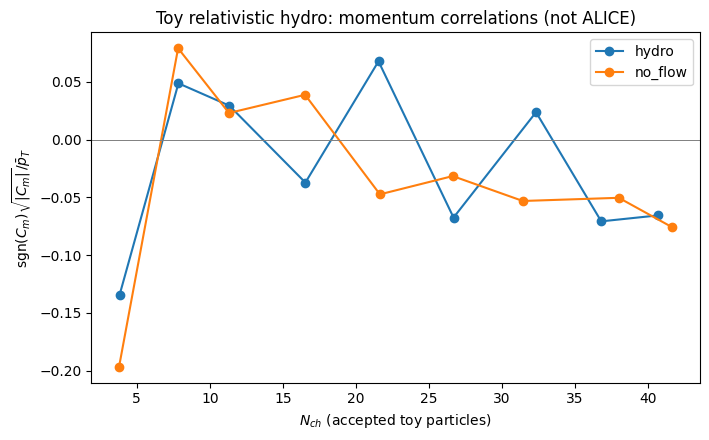

,nch,events,C_m,scaled,mean_pt,scenario
0,3.8261,23,-0.0035,-0.1343,0.4398,hydro
1,7.8512,1398,0.0005,0.0487,0.4464,hydro
2,11.3360,1113,0.0002,0.0294,0.4595,hydro
3,16.5436,298,-0.0003,-0.0372,0.4820,hydro
4,21.5492,122,0.0011,0.0678,0.4896,hydro
5,26.6875,32,-0.0012,-0.0675,0.5050,hydro
6,32.3333,6,0.0001,0.0237,0.5138,hydro
7,36.8000,5,-0.0014,-0.0708,0.5202,hydro
8,40.6667,3,-0.0010,-0.0657,0.4803,hydro
9,3.7857,14,-0.0062,-0.1968,0.4001,no_flow


In [ ]:
def cm_by_bins(particles, step=3):
    lens=np.array([len(p) for p in particles])
    lo=int(np.floor(lens.min()/step)*step)
    hi=int(np.ceil((lens.max()+1)/step)*step)
    entries=[]
    for left in range(lo,hi,step):
        ids=np.flatnonzero((lens>=left)&(lens<left+step)&(lens>=2))
        if len(ids)<3:continue
        inclusive=np.concatenate([particles[i] for i in ids]).mean()
        ce=[]
        for i in ids:
            delta=particles[i]-inclusive
            ce.append((delta.sum()**2-np.dot(delta,delta))/(len(delta)*(len(delta)-1)))
        cm=float(np.mean(ce))
        entries.append({'nch':float(np.mean(lens[ids])),'events':len(ids),'C_m':cm,
                        'scaled':float(np.sign(cm)*np.sqrt(abs(cm))/inclusive),'mean_pt':inclusive})
    return pd.DataFrame(entries)

cmp=[]
fig,ax=plt.subplots(figsize=(7.2,4.5))
for name,values in particle_store.items():
    table=cm_by_bins(values, step=5)
    table['scenario']=name;cmp.append(table)
    ax.plot(table.nch,table.scaled,'o-',label=name)
ax.axhline(0,color='gray',lw=.7)
ax.set_xlabel(r'$N_{ch}$ (accepted toy particles)')
ax.set_ylabel(r'$\mathrm{sgn}(C_m)\sqrt{|C_m|}/\bar p_T$')
ax.set_title('Toy relativistic hydro: momentum correlations (not ALICE)')
ax.legend();plt.tight_layout();plt.savefig(OUT/'hydro_cm.png',dpi=160);plt.show()
if cmp:display(pd.concat(cmp,ignore_index=True).round(4));pd.concat(cmp).to_csv(OUT/'hydro_cm.csv',index=False)


Hydro:
  N events = 3000
  Nch min = 3
  Nch max = 41
  mean = 10.864666666666666
  std = 4.441050085754157
  unique Nch = 38

No-flow:
  Nch min = 2
  Nch max = 43
  mean = 10.803666666666667
  std = 4.481571307329879
  unique Nch = 38


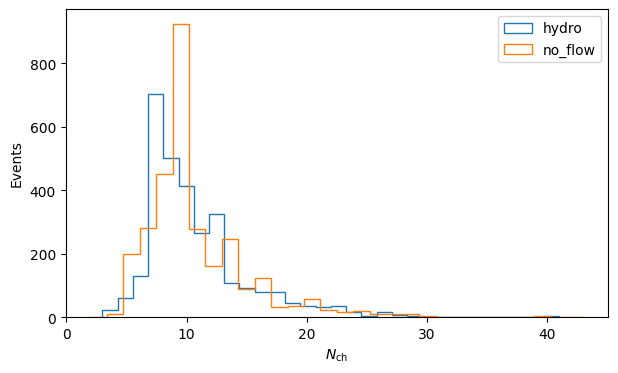

In [ ]:
print("Hydro:")
print("  N events =", len(df))
print("  Nch min =", df['nch'].min())
print("  Nch max =", df['nch'].max())
print("  mean =", df['nch'].mean())
print("  std =", df['nch'].std())
print("  unique Nch =", df['nch'].nunique())

print("\nNo-flow:")
print("  Nch min =", df['nch_no_flow'].min())
print("  Nch max =", df['nch_no_flow'].max())
print("  mean =", df['nch_no_flow'].mean())
print("  std =", df['nch_no_flow'].std())
print("  unique Nch =", df['nch_no_flow'].nunique())

plt.figure(figsize=(7,4))
plt.hist(df['nch'], bins=30, histtype='step', label='hydro')
plt.hist(df['nch_no_flow'], bins=30, histtype='step', label='no_flow')
plt.xlabel(r'$N_{\rm ch}$')
plt.ylabel('Events')
plt.legend()
plt.show()

In [ ]:
def print_bin_statistics(particles, step=3):

    lens = np.array([len(p) for p in particles])

    lo = int(np.floor(lens.min() / step) * step)
    hi = int(np.ceil((lens.max() + 1) / step) * step)

    for left in range(lo, hi, step):

        ids = np.flatnonzero(
            (lens >= left) &
            (lens < left + step) &
            (lens >= 2)
        )

        print(
            f"Nch [{left:2d},{left+step:2d}): "
            f"{len(ids):3d} events"
        )


print("HYDRO")
print_bin_statistics(
    particle_store['hydro'],
    step=3
)

print("\nNO FLOW")
print_bin_statistics(
    particle_store['no_flow'],
    step=3
)

HYDRO
Nch [ 3, 6):  84 events
Nch [ 6, 9): 835 events
Nch [ 9,12): 1181 events
Nch [12,15): 434 events
Nch [15,18): 213 events
Nch [18,21): 121 events
Nch [21,24):  70 events
Nch [24,27):  34 events
Nch [27,30):  14 events
Nch [30,33):   3 events
Nch [33,36):   4 events
Nch [36,39):   4 events
Nch [39,42):   3 events

NO FLOW
Nch [ 0, 3):   1 events
Nch [ 3, 6):  73 events
Nch [ 6, 9): 874 events
Nch [ 9,12): 1201 events
Nch [12,15): 407 events
Nch [15,18): 211 events
Nch [18,21):  95 events
Nch [21,24):  71 events
Nch [24,27):  30 events
Nch [27,30):  21 events
Nch [30,33):   4 events
Nch [33,36):   3 events
Nch [36,39):   3 events
Nch [39,42):   4 events
Nch [42,45):   2 events


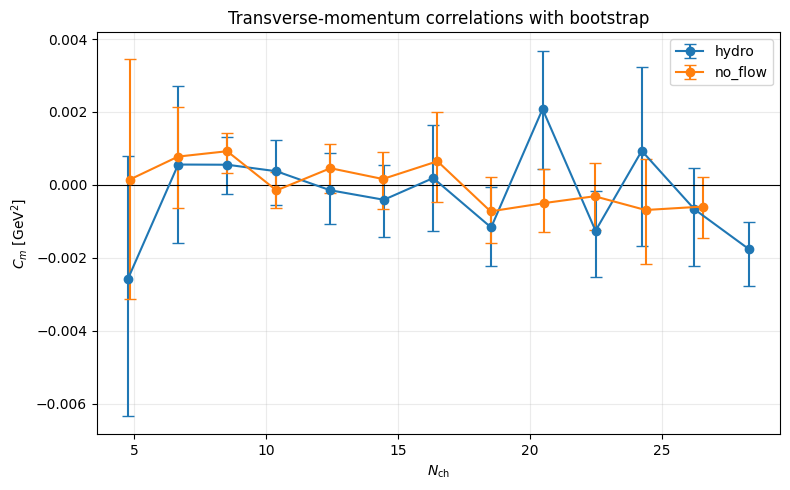

,scenario,nch,events,C_m,low,high
0,hydro,4.762500,80,-0.002582,-0.006339,0.000781
1,hydro,6.669192,396,0.000559,-0.001597,0.002717
2,hydro,8.533475,941,0.000553,-0.000256,0.001326
3,hydro,10.390280,679,0.000375,-0.000551,0.001221
4,hydro,12.428135,327,-0.000146,-0.001086,0.000882
5,hydro,14.465000,200,-0.000408,-0.001430,0.000554
6,hydro,16.333333,120,0.000188,-0.001254,0.001648
7,hydro,18.529412,85,-0.001167,-0.002228,-0.000070
8,hydro,20.478261,69,0.002079,0.000430,0.003683
9,hydro,22.486486,37,-0.001257,-0.002538,-0.000179


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def cm_estimate(events):
    events = [np.asarray(e) for e in events if len(e) >= 2]

    if len(events) < 3:
        return np.nan

    n = np.array([len(e) for e in events])
    mean_inclusive = sum(e.sum() for e in events) / n.sum()

    correlations = []

    for e in events:
        d = e - mean_inclusive
        correlations.append(
            (d.sum()**2 - np.dot(d, d))
            / (len(e) * (len(e) - 1))
        )

    return np.mean(correlations)


rng_boot = np.random.default_rng(20261020)

N_BOOT = 500
BIN_WIDTH = 2
MIN_EVENTS = 10

results = []

for scenario, particles in particle_store.items():

    multiplicities = np.array([len(p) for p in particles])

    left_min = int(multiplicities.min() // BIN_WIDTH * BIN_WIDTH)
    right_max = int(np.ceil((multiplicities.max()+1) / BIN_WIDTH) * BIN_WIDTH)

    for left in range(left_min, right_max, BIN_WIDTH):

        ids = np.flatnonzero(
            (multiplicities >= left) &
            (multiplicities < left + BIN_WIDTH)
        )

        if len(ids) < MIN_EVENTS:
            continue

        selected = [particles[i] for i in ids]

        cm = cm_estimate(selected)

        boot = []

        for _ in range(N_BOOT):

            selected_ids = rng_boot.integers(
                0, len(selected), size=len(selected)
            )

            sample = [selected[j] for j in selected_ids]
            boot.append(cm_estimate(sample))

        low, high = np.nanpercentile(boot, [2.5, 97.5])

        results.append({
            "scenario": scenario,
            "nch": np.mean(multiplicities[ids]),
            "events": len(ids),
            "C_m": cm,
            "low": low,
            "high": high
        })


cm_bootstrap = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 5))

for scenario, g in cm_bootstrap.groupby("scenario"):

    ax.errorbar(
        g["nch"],
        g["C_m"],
        yerr=[
            g["C_m"] - g["low"],
            g["high"] - g["C_m"]
        ],
        marker="o",
        capsize=4,
        linewidth=1.5,
        label=scenario
    )

ax.axhline(0, color="black", linewidth=0.8)

ax.set_xlabel(r"$N_{\mathrm{ch}}$")
ax.set_ylabel(r"$C_m$ [GeV$^2$]")
ax.set_title("Transverse-momentum correlations with bootstrap")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

display(cm_bootstrap)

Eventos hidrodinámicos: 3000

hydro
Eventos: 3000
Nch mínimo: 3
Nch máximo: 41
Media: 10.864666666666666
Desviación estándar: 4.440309849048324


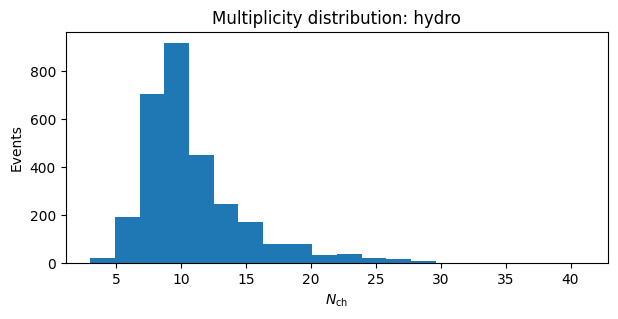


no_flow
Eventos: 3000
Nch mínimo: 2
Nch máximo: 43
Media: 10.803666666666667
Desviación estándar: 4.480824316524311


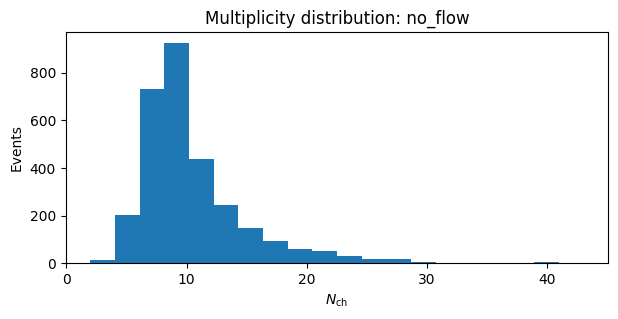

In [ ]:
print("Eventos hidrodinámicos:", len(df))

for scenario, particles in particle_store.items():
    nch = np.array([len(p) for p in particles])

    print(f"\n{scenario}")
    print("Eventos:", len(nch))
    print("Nch mínimo:", nch.min())
    print("Nch máximo:", nch.max())
    print("Media:", nch.mean())
    print("Desviación estándar:", nch.std())

    plt.figure(figsize=(7, 3))
    plt.hist(nch, bins=20)
    plt.title(f"Multiplicity distribution: {scenario}")
    plt.xlabel(r"$N_{\mathrm{ch}}$")
    plt.ylabel("Events")
    plt.show()




* **A difference between the flow and no-flow emission controls is not evidence of thermalization.** Both branches experienced the same hydrodynamic evolution of the energy density, with only the last-stage velocity boost disabled.
* The EOS, fixed-$	au$ emission, boost invariance and smooth initial longitudinal structure are strong simplifications. There is no viscosity or hadronic rescattering.
* Our $q_\mathrm{proxy}$ is a transverse inhomogeneity diagnostic



In [ ]:
# Optional: download figures and tables as a ZIP from Colab.
import shutil
archive=shutil.make_archive('hydro_memory_outputs','zip',OUT)
print('Saved:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Not running in Colab; files are in',OUT)


Saved: /content/hydro_memory_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>